# Validating new SOCRATES spectral files

This notebook checks the new spectral files (`Snowline`, `Breezehome`, `Volenfell`) in three ways:

1. **Band consistency.** On fixed T(p) profiles, the outgoing longwave radiation (OLR) and the emission spectrum should not depend on the number of bands. Each family is compared with its own version with the most bands.
2. **Converged profiles.** Temperature profiles in radiative-convective equilibrium (RCE) are solved on a simple magma-ocean case, using the files with up to `N_RCE_MAX` bands.
3. **Old files.** The new files are compared with `Honeyside/48` and `Oak/318` for compositions whose absorbers are in both. `Volenfell` has other absorbers, so it is not part of this comparison.

| File | Absorbers | Cases run |
|---|---|---|
| Snowline | H₂O; H₂O–H₂O continuum | steam |
| Breezehome | H₂O, CO₂, CO, O₂, O₃, SO₂, OCS, S₂; four continua | steam, mixed |
| Volenfell | CO, O₂, SiO, TiO, MgO, Na, K, Fe; O₂–O₂ continuum | rock vapour |
| Honeyside/48 | H₂O, CO₂, CO, SO₂ and 8 others; nine continua | steam, mixed |
| Oak/318 | H₂O; H₂O–H₂O continuum | steam |

The band counts are read from the folders under `NEW_DIR`, so new versions (e.g. of Breezehome) are included when the notebook is re-run. A full run takes about 15 minutes, most of it reading the k-tables and solving for RCE. Figures are saved to `out/spectral_validation/`.

In [1]:
using Pkg
const AGNI_DIR = abspath(joinpath(pwd(), "..", "..", ".."))    # notebook lives in misc/validation/physics/
Pkg.activate(AGNI_DIR)
using AGNI, Plots, Printf, Statistics, Logging
import AGNI: atmosphere, solver, energy, setpt, consts

global_logger(ConsoleLogger(stderr, Logging.Warn))    # show only warnings and errors from AGNI

const NEW_DIR = joinpath(AGNI_DIR, "res", "spectral_files", "nogit_new_spectralfiles")   # change when the files move
const OLD_DIR = joinpath(AGNI_DIR, "res", "spectral_files")
const STAR    = joinpath(AGNI_DIR, "res", "stellar_spectra", "sun.txt")
const OUT_DIR = joinpath(AGNI_DIR, "out", "spectral_validation"); mkpath(OUT_DIR)

  Activating 

project at `~/Projects/AGNI`
[ Info: Precompiling AGNI [ede838c1-9ec3-4ebe-8ae8-da4091b3f21c] (caches not reused: 5 for different dependency version already loaded, 3 for different Julia build configuration, 1 for different source file path)


Precompiling packages...


   0.5 s  ✓ Libtiff_jll


   0.6 s  ✓ Coverage


...

Precompiling packages...


   0.5 s  ✓ IJuliaExt (serial)
  1 dependency successfully precompiled in 2 seconds
[ Info: Precompiling IJuliaExt [6e0e26ac-fb43-584e-b323-fdbabcf95812] (caches not reused: 1 for different dependency version already loaded, 2 for different Julia build configuration)


Precompiling packages...


   1.1 s  ✓ IJuliaExt (serial)
  1 dependency successfully precompiled in 1 seconds


"/home/harrison/Projects/AGNI/out/spectral_validation"

In [2]:
# Earth-sized planet at 1 AU from the Sun. The stellar heating is then small next to the cooling flux
# of a magma ocean, so the RCE profiles are set mostly by the longwave
INSTELLATION = 1361.0              # [W m-2]
S0_FACT, ZENITH = 0.375, 54.74     # instellation scale factor, zenith angle [deg]
GRAVITY, RADIUS = 9.81, 6.371e6    # [m s-2], [m]
NLEV       = 40
P_TOP      = 1e-5                  # [bar], lowest pressure in the new k-tables
STRAT_FRAC = 1/3                   # fixed profiles: dry adiabat, isothermal where it would be colder than T_surf/3
N_RCE_MAX  = 128                   # new files: solve for RCE only with up to this many bands

# Composition, surface pressure [bar], T_surf of the fixed profiles [K], T_surf of the RCE solve [K], and the
# stratosphere of its initial guess as a fraction of T_surf (rock vapour does not converge from T_surf/3).
# The steam and mixed cases stay below 2895 K, the hottest temperature in the Honeyside k-tables
CASES = Dict(
    "steam" => (x = Dict("H2O" => 1.0), p_surf = 100.0, ts = [1000.0, 1800.0, 2600.0], ts_rce = 2500.0, frac_rce = 1/3),
    "mixed" => (x = Dict("H2O" => 0.7, "CO2" => 0.2, "CO" => 0.05, "SO2" => 0.05), p_surf = 100.0,
                ts = [1000.0, 1800.0, 2600.0], ts_rce = 2500.0, frac_rce = 1/3),
    # illustrative rock vapour, chosen so that every Volenfell absorber contributes; not from a chemistry calculation
    "rock"  => (x = Dict("O2" => 0.30, "Na" => 0.30, "SiO" => 0.20, "Fe" => 0.10, "MgO" => 0.05,
                         "K" => 0.03, "CO" => 0.0195, "TiO" => 5e-4), p_surf = 0.1,
                ts = [2000.0, 3000.0, 4000.0], ts_rce = 3000.0, frac_rce = 1/2),
)

# Cases run with each new family (every band count on disk), and with each old file
FAMILIES = ["Snowline" => ["steam"], "Breezehome" => ["steam", "mixed"], "Volenfell" => ["rock"]]
OLD      = ["Honeyside" => (48, ["steam", "mixed"]), "Oak" => (318, ["steam"])]

# Band counts on disk, read once so that files added during a run are ignored until the next run
NB = Dict(f => sort([n for n in tryparse.(Int, readdir(joinpath(NEW_DIR, f)))
                     if !isnothing(n) && isfile(joinpath(NEW_DIR, f, string(n), f * ".sf"))]) for (f, _) in FAMILIES)

JOBS = [(fam = f, nb = n, case = cn, rce = n <= N_RCE_MAX, sf = joinpath(NEW_DIR, f, string(n), f * ".sf"))
        for (f, cs) in FAMILIES for n in NB[f] for cn in cs]
append!(JOBS, [(fam = f, nb = n, case = cn, rce = true, sf = joinpath(OLD_DIR, f, string(n), f * ".sf"))
               for (f, (n, cs)) in OLD for cn in cs])
for j in JOBS
    @printf("%-10s %5d bands  %-6s RCE %-5s %s\n", j.fam, j.nb, j.case, j.rce, relpath(j.sf, OLD_DIR))
end

Snowline      32 bands  steam  RCE true  nogit_new_spectralfiles/Snowline/32/Snowline.sf
Snowline      64 bands  steam  RCE true  nogit_new_spectralfiles/Snowline/64/Snowline.sf


Snowline     128 bands  steam  RCE true  nogit_new_spectralfiles/Snowline/128/Snowline.sf
Snowline     256 bands  steam  RCE false nogit_new_spectralfiles/Snowline/256/Snowline.sf
Snowline    4096 bands  steam  RCE false nogit_new_spectralfiles/Snowline/4096/Snowline.sf
Breezehome   128 bands  steam  RCE true  nogit_new_spectralfiles/Breezehome/128/Breezehome.sf
Breezehome   128 bands  mixed  RCE true  nogit_new_spectralfiles/Breezehome/128/Breezehome.sf
Breezehome   256 bands  steam  RCE false nogit_new_spectralfiles/Breezehome/256/Breezehome.sf
Breezehome   256 bands  mixed  RCE false nogit_new_spectralfiles/Breezehome/256/Breezehome.sf
Volenfell     32 bands  rock   RCE true  nogit_new_spectralfiles/Volenfell/32/Volenfell.sf
Volenfell     64 bands  rock   RCE true  nogit_new_spectralfiles/Volenfell/64/Volenfell.sf
Volenfell    128 bands  rock   RCE true  nogit_new_spectralfiles/Volenfell/128/Volenfell.sf
Volenfell    256 bands  rock   RCE false nogit_new_spectralfiles/Volenfell/256/

In [3]:
# Set up and allocate an atmosphere for job j, writing its runtime spectral file to a folder of its own
function make_atmos(j)
    c   = CASES[j.case]
    a   = atmosphere.Atmos_t()
    dir = mkpath(joinpath(OUT_DIR, "$(j.fam)_$(j.nb)_$(j.case)"))
    atmosphere.setup!(a, AGNI_DIR, dir, j.sf, INSTELLATION, S0_FACT, 0.0, ZENITH, c.ts_rce,
                      GRAVITY, RADIUS, NLEV, c.p_surf, P_TOP, c.x, "";
                      flag_gcontinuum=true, flag_rayleigh=false, overlap_method="ee") || error("setup! failed: $(j.sf)")
    atmosphere.allocate!(a, STAR) || error("allocate! failed: $(j.sf)")
    return a
end

# Prescribe T(p) with surface temperature ts: isothermal, or a dry adiabat with an isothermal stratosphere at frac*ts
function prescribe!(a, ts; iso=false, frac=STRAT_FRAC)
    a.tmp_surf = ts
    if iso
        setpt.isothermal!(a, ts)
    else
        setpt.dry_adiabat!(a)
        setpt.stratosphere!(a, frac * ts)
    end
    atmosphere.calc_layer_props!(a) || @warn "calc_layer_props! failed"
end

# Run job j: fluxes on the fixed profiles, the cost of one radiative transfer call, and an RCE solve if j.rce
function run_job(j)
    c = CASES[j.case]
    t_alloc = @elapsed a = make_atmos(j)
    r = Dict{Symbol,Any}(:lo => copy(a.bands_min), :hi => copy(a.bands_max), :t_alloc => t_alloc)

    # isothermal: OLR = σT⁴ for any opacity, since the surface is black
    r[:iso] = map(c.ts) do ts
        prescribe!(a, ts; iso=true)
        energy.calc_fluxes!(a; radiative=true)
        a.flux_u_lw[1]
    end

    # adiabat and stratosphere: OLR, and upward LW flux at TOA in each band
    r[:fix] = map(c.ts) do ts
        prescribe!(a, ts)
        energy.calc_fluxes!(a; radiative=true)
        (olr = a.flux_u_lw[1], F = a.band_u_lw[1, :])
    end
    r[:t_rt] = @elapsed(for _ in 1:5; energy.calc_fluxes!(a; radiative=true); end) / 5

    # RCE with fixed T_surf (sol_type=1), from an adiabat with stratosphere at frac_rce*ts_rce; no condensation or sensible heat
    if j.rce
        prescribe!(a, c.ts_rce; frac=c.frac_rce)
        r[:t_rce] = @elapsed ok = solver.solve_energy!(a; sol_type=1, method=1, ls_method=3, dx_max=200.0,
                                    latent=false, sens_heat=false, conduct=false, rainout=false, oceans=false,
                                    conv_atol=1e-1, conv_rtol=1e-3, max_steps=300, max_runtime=1800.0,
                                    modplot=0, save_frames=false, modprint=0)
        r[:rce] = (ok = ok, p = a.p ./ 1e5, tmp = copy(a.tmp), olr = a.flux_u_lw[1], ftot = copy(a.flux_tot))
    end
    atmosphere.deallocate!(a)
    return r
end

# Integrate band fluxes F on wavelength bands [lo, hi] over the bands [LO, HI], taking F as uniform in wavelength within each band
rebin(lo, hi, F, LO, HI) = [sum(@. F * max(0.0, min(hi, HI[k]) - max(lo, LO[k])) / (hi - lo)) for k in eachindex(LO)]

# Fraction of the OLR in the wrong bands, Σ|F − F_ref| / ΣF_ref, on the bands of r, for fixed profile k
function spec_err(r, rref, k)
    R = rebin(rref[:lo], rref[:hi], rref[:fix][k].F, r[:lo], r[:hi])
    return sum(abs.(r[:fix][k].F .- R)) / sum(R)
end

spec_err (generic function with 1 method)

## Run all spectral files

Each spectral file is loaded once per case, then freed. The first file's load time includes compilation.

In [4]:
RES = Dict{Tuple{String,Int,String},Dict{Symbol,Any}}()
for j in JOBS
    @printf("%-10s %5d bands  %-6s", j.fam, j.nb, j.case)
    r = RES[(j.fam, j.nb, j.case)] = run_job(j)
    @printf("  load %5.1f s   RT call %8.2f ms", r[:t_alloc], 1e3 * r[:t_rt])
    j.rce && @printf("   RCE %s in %5.1f s", r[:rce].ok ? "converged" : "NOT CONVERGED", r[:t_rce])
    println()
end

Snowline      32 bands  steam 

  load  28.5 s   RT call     4.87 ms   RCE converged in  14.8 s


Snowline      64 bands  steam 

  load  24.7 s   RT call     9.59 ms   RCE converged in  27.7 s


Snowline     128 bands  steam 

...

  load  15.5 s   RT call    12.57 ms   RCE converged in  42.4 s


Honeyside     48 bands  mixed 

  load  15.6 s   RT call    12.43 ms   RCE converged in  46.4 s


Oak          318 bands  steam 

  load  12.6 s   RT call    61.80 ms   RCE converged in 328.6 s

## Checks

* **Isothermal.** With T = T_surf everywhere and a black surface, the OLR is σT⁴ for any opacity, apart from the Planck flux outside the band range (below 10⁻⁴ of σT⁴ for these files and temperatures). This tests each file's band limits and Planck integration, not its k-coefficients. Errors above 10⁻³ are marked `*`.
  * Known cause: AGNI tabulates the band-integrated Planck function with SOCRATES `prep_spec`. Its `CALC_PLANCK_TBL` (`src/general/calc_planck_tbl.f`) uses Simpson's rule on $N \approx 1.4388\,\Delta\nu / (10^{-4}\,T)$ intervals, with Δν in cm⁻¹. When N is odd, the result is low by $1/(3N)$. For the 4096-band files every band is 12.15 cm⁻¹ wide, so all bands have the same N at a given T. The error then has the same sign in every band, about 0.2–0.5 % between 1000 and 2600 K, and zero at temperatures where N is even. The reference spectra in sections 1 and 3 have this error too.
* **Band sum.** The band fluxes add up to the OLR.
* **Finite and positive.** The fluxes are finite, and the RCE temperatures are positive.
* **RCE.** The solver converged, and the net flux is uniform with height. The spread is (max − min)/mean of the net flux.

The plot shows the time for one radiative transfer call (longwave and shortwave, 40 levels), which sets the cost of the RCE solve.

file       bands case      iso err  Σband err  finite   RCE conv  min T [K]     ΔF_net
Snowline      32 steam    1.4e-05     0.0e+00    true

       true      213.7    5.5e-04
Snowline      64 steam    5.8e-05     0.0e+00    true       true      215.9    2.5e-04
Snowline     128 steam    2.1e-05     0.0e+00    true       true      212.2    5.8e-04
Snowline     256 steam    8.7e-05     0.0e+00    true
Snowline    4096 steam    5.0e-03*    0.0e+00    true
Breezehome   128 steam    2.1e-05     0.0e+00    true       true      212.2    5.8e-04
Breezehome   128 mixed    2.1e-05     0.0e+00    true       true      466.1    8.9e-04
Breezehome   256 steam    8.7e-05     0.0e+00    true
Breezehome   256 mixed    8.7e-05     0.0e+00    true
Volenfell     32 rock     3.8e-06     0.0e+00    true       true     1399.7    6.5e-04
Volenfell     64 rock     7.2e-05     0.0e+00    true       true     1423.6    1.9e-04
Volenfell    128 rock     9.1e-05     0.0e+00    true       true     1424.8    1.0e-04
Volenfell    256 rock     3.5e-04     0.0e+00    true
Volenfell   4096 rock     1.8e-03*    0.0e+00    true
Honeyside     48 steam    5.0e-05

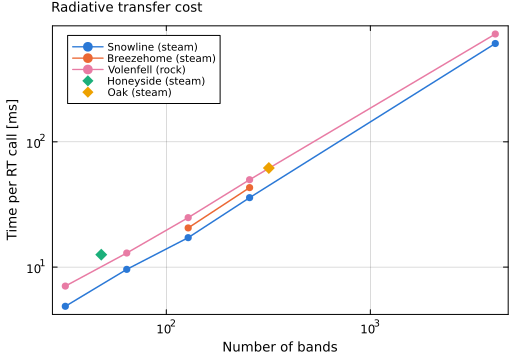

In [5]:
σT4(T) = consts.σSB * T^4
@printf("%-10s %5s %-6s %10s %10s %7s %10s %10s %10s\n", "file", "bands", "case", "iso err", "Σband err",
        "finite", "RCE conv", "min T [K]", "ΔF_net")
for j in JOBS
    r, c = RES[(j.fam, j.nb, j.case)], CASES[j.case]
    e_iso = maximum(abs.(r[:iso] ./ σT4.(c.ts) .- 1))
    e_sum = maximum(abs(sum(f.F) / f.olr - 1) for f in r[:fix])
    fin   = all(isfinite(f.olr) && all(isfinite, f.F) for f in r[:fix]) && all(isfinite, r[:iso])
    @printf("%-10s %5d %-6s %9.1e%s %10.1e %7s", j.fam, j.nb, j.case, e_iso, e_iso > 1e-3 ? "*" : " ", e_sum, fin)
    if j.rce
        q = r[:rce]
        fin_rce = all(isfinite, q.tmp) && all(isfinite, q.ftot)
        @printf(" %10s %10.1f %10.1e", q.ok && fin_rce, minimum(q.tmp), (maximum(q.ftot) - minimum(q.ftot)) / abs(mean(q.ftot)))
    end
    println()
end

default(framestyle=:box, grid=true, gridalpha=0.15, fontfamily="sans-serif", legendfontsize=7,
        guidefontsize=9, tickfontsize=8, titlefontsize=9, titlelocation=:left)
FCOL   = Dict("Snowline" => "#2a78d6", "Breezehome" => "#eb6834", "Honeyside" => "#1baf7a",
              "Oak" => "#eda100", "Volenfell" => "#e87ba4")     # one colour per file family
REFCOL = "#52514e"                                               # reference spectra

pB = plot(xscale=:log10, yscale=:log10, xlabel="Number of bands", ylabel="Time per RT call [ms]",
          legend=:topleft, size=(520, 360), title="Radiative transfer cost")
for (f, cs) in FAMILIES
    ns = NB[f]
    plot!(pB, ns, [1e3 * RES[(f, n, cs[1])][:t_rt] for n in ns], color=FCOL[f], lw=1.5,
          marker=:circle, ms=4, msw=0, label="$f ($(cs[1]))")
end
for (f, (n, cs)) in OLD
    scatter!(pB, [n], [1e3 * RES[(f, n, cs[1])][:t_rt]], color=FCOL[f], marker=:diamond, ms=6, msw=0, label="$f ($(cs[1]))")
end
savefig(pB, joinpath(OUT_DIR, "rt_cost.png"))
pB

In [6]:
RAMP = ["#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"]    # ordinal blue: light = few bands, dark = many
ordcol(i, m) = m == 1 ? RAMP[end] : get(cgrad(RAMP), (i - 1) / (m - 1))
pos(v) = v > 0 ? v : NaN                                            # NaN where there is no flux (log axis)
XL = (0.2, 100.0)                                                   # wavelengths shown [µm]

# Step curve of band values v over wavelength bands [lo, hi] [m], in µm and sorted by wavelength
function steps(lo, hi, v)
    o = sortperm(lo)
    return vec(permutedims([lo[o] hi[o]])) .* 1e6, vec(permutedims([v[o] v[o]]))
end

# Print OLR difference and spectral error [%] of the runs in keys relative to run kref, for case cn
function report(cn, kref, keys)
    c, rref = CASES[cn], RES[kref]
    @printf("\n%s case, reference %s/%d. Columns are T_surf = %s K\n", cn, kref[1], kref[2], join(Int.(c.ts), ", "))
    @printf("%-10s %5s   %-24s %-24s\n", "file", "bands", "OLR - OLR_ref [%]", "spectral error [%]")
    for k in keys
        r  = RES[k]
        dO = join([@sprintf("%+8.2f", 100 * (r[:fix][i].olr / rref[:fix][i].olr - 1)) for i in eachindex(c.ts)])
        eS = join([@sprintf("%8.2f", 100 * spec_err(r, rref, i)) for i in eachindex(c.ts)])
        @printf("%-10s %5d   %-24s %-24s\n", k[1], k[2], dO, eS)
    end
end

# Spectra of fixed profile i for entries (key, label, colour, lw): flux density on top, and below
# the band flux over the reference rebinned onto each file's bands (bands with < 1e-4 of the OLR left out)
function spectra_panels(title, kref, entries, i)
    rref = RES[kref]
    pS = plot(xscale=:log10, yscale=:log10, xlims=XL, ylabel="TOA upward LW [W m⁻² µm⁻¹]", title=title, legend=:bottomleft)
    pR = plot(xscale=:log10, xlims=XL, ylims=(0.5, 1.5), xlabel="Wavelength [µm]", ylabel="Band flux / reference", legend=false)
    for (k, label, col, lw) in entries
        r, F = RES[k], RES[k][:fix][i].F
        plot!(pS, steps(r[:lo], r[:hi], pos.(F ./ (1e6 .* (r[:hi] .- r[:lo]))))..., color=col, lw=lw, label=label)
        k == kref && continue
        R = rebin(rref[:lo], rref[:hi], rref[:fix][i].F, r[:lo], r[:hi])
        plot!(pR, steps(r[:lo], r[:hi], ifelse.(R .> 1e-4 * rref[:fix][i].olr, F ./ R, NaN))..., color=col, lw=lw)
    end
    hline!(pR, [1.0], color=:gray, lw=0.8)
    return pS, pR
end

# Print RCE results for the runs in keys, relative to run kref
function rce_report(kref, keys)
    qref = RES[kref][:rce]
    for k in keys
        q = RES[k][:rce]
        @printf("%-10s %-6s %5d bands  converged %-5s  OLR %9.4g W m⁻² (%+6.2f%%)  net flux %9.4g W m⁻²  max|T - T_ref| %6.1f K\n",
                k[1], k[3], k[2], q.ok, q.olr, 100 * (q.olr / qref.olr - 1), mean(q.ftot), maximum(abs.(q.tmp .- qref.tmp)))
    end
end

# RCE temperature profiles for entries (key, label, colour) on top, and their difference from run kref below
function tp_panels(title, kref, entries)
    qref = RES[kref][:rce]
    pT = plot(yflip=true, yscale=:log10, xlabel="Temperature [K]", ylabel="Pressure [bar]", title=title, legend=:bottomleft)
    pD = plot(yflip=true, yscale=:log10, xlabel="T - T_ref [K]", ylabel="Pressure [bar]", legend=false)
    for (k, label, col) in entries
        q = RES[k][:rce]
        plot!(pT, q.tmp, q.p, color=col, lw=1.5, label=label * (q.ok ? "" : " (not converged)"))
        plot!(pD, q.tmp .- qref.tmp, q.p, color=col, lw=1.5)
    end
    vline!(pD, [0.0], color=:gray, lw=0.8)
    return pT, pD
end

# Two-row figure with one column per (top, bottom) pair, saved as name.png
function fig2rows(panels, name; h=640)
    fig = plot(first.(panels)..., last.(panels)..., layout=grid(2, length(panels), heights=[0.6, 0.4]),
               size=(380 * length(panels), h), left_margin=5Plots.mm, bottom_margin=5Plots.mm)
    savefig(fig, joinpath(OUT_DIR, name * ".png"))
    return fig
end

fig2rows (generic function with 1 method)

## 1. Band consistency on fixed profiles

The fixed profiles are a dry adiabat from T_surf, with an isothermal stratosphere at T_surf/3. For each family and case, the reference is the version with the most bands. Two numbers are reported for each T_surf:

* the OLR difference from the reference;
* the spectral error, $\sum_b |F_b - F_b^\mathrm{ref}| / \sum_b F_b^\mathrm{ref}$, on the bands of the coarser file. $F_b^\mathrm{ref}$ is the reference flux integrated over band $b$. This is the fraction of the OLR placed in the wrong bands. It can be large even when the OLR agrees.

The reference is rebinned by taking its flux as uniform within each of its own bands. This is exact where the edges of the coarser file are also reference edges. The new files have one band from 10 to 250 cm⁻¹ and N − 1 equal bands from 250 to 50 000 cm⁻¹, so the edges match the 4096-band file only when N − 1 divides 4095 (e.g. N = 64, but not 32, 128 or 256). Otherwise, only the reference band that straddles each edge is split wrongly. This is at most a fraction 2 × 12/(width of the coarse band in cm⁻¹) of a band's flux, and usually much less.


steam case, reference Snowline/4096. Columns are T_surf = 1000, 1800, 2600 K
file       bands   OLR - OLR_ref [%]        spectral error [%]      


Snowline      32      +0.00   -0.24  -14.76     0.00    0.88   14.87
Snowline      64      +0.00   -0.10   -7.55     0.00    0.61    7.64


Snowline     128      +0.00   +0.01   -6.75     0.01    0.56    6.86
Snowline     256      -0.00   +0.13   -3.70     0.01    0.49    3.86
Snowline    4096      +0.00   +0.00   +0.00     0.00    0.00    0.00

steam case, reference Breezehome/256. Columns are T_surf = 1000, 1800, 2600 K
file       bands   OLR - OLR_ref [%]        spectral error [%]      
Breezehome   128      +0.00   -0.12   -3.17     0.10    0.21    3.49
Breezehome   256      +0.00   +0.00   +0.00     0.00    0.00    0.00

mixed case, reference Breezehome/256. Columns are T_surf = 1000, 1800, 2600 K
file       bands   OLR - OLR_ref [%]        spectral error [%]      
Breezehome   128      +0.00   -0.24   -4.83     0.10    0.34    5.02
Breezehome   256      +0.00   +0.00   +0.00     0.00    0.00    0.00

rock case, reference Volenfell/4096. Columns are T_surf = 2000, 3000, 4000 K
file       bands   OLR - OLR_ref [%]        spectral error [%]      
Volenfell     32     -12.73  -11.54   -7.12    12.78   12.24    9.10
Volen

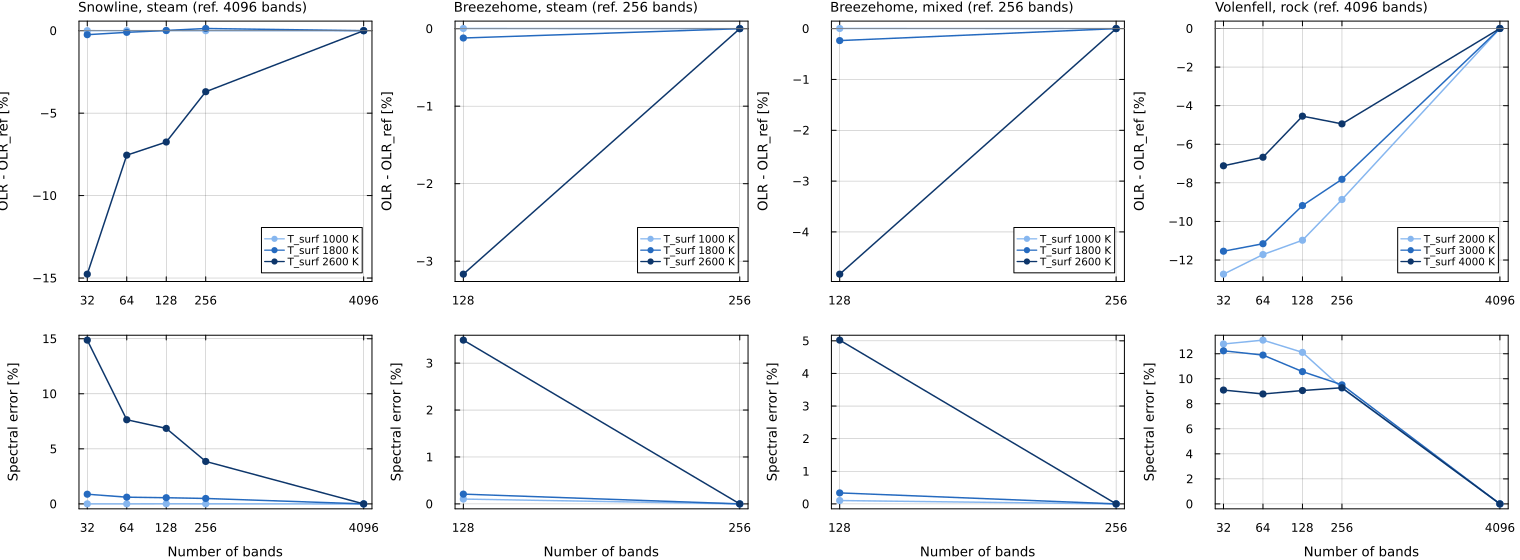

In [7]:
S1 = [(f, cn) for (f, cs) in FAMILIES for cn in cs]
for (f, cn) in S1
    ns = NB[f]
    report(cn, (f, ns[end], cn), [(f, n, cn) for n in ns])
end

panels = map(S1) do (f, cn)
    c, ns = CASES[cn], NB[f]
    rref = RES[(f, ns[end], cn)]
    pO = plot(xscale=:log2, xticks=(ns, string.(ns)), ylabel="OLR - OLR_ref [%]",
              title="$f, $cn (ref. $(ns[end]) bands)", legend=:bottomright)
    pE = plot(xscale=:log2, xticks=(ns, string.(ns)), xlabel="Number of bands", ylabel="Spectral error [%]", legend=false)
    for (k, ts) in enumerate(c.ts)
        col = ordcol(k, length(c.ts))
        plot!(pO, ns, [100 * (RES[(f, n, cn)][:fix][k].olr / rref[:fix][k].olr - 1) for n in ns],
              color=col, lw=1.5, marker=:circle, ms=4, msw=0, label=@sprintf("T_surf %.0f K", ts))
        plot!(pE, ns, [100 * spec_err(RES[(f, n, cn)], rref, k) for n in ns], color=col, lw=1.5, marker=:circle, ms=4, msw=0)
    end
    hline!(pO, [0.0], color=:gray, lw=0.8, label="")
    (pO, pE)
end
fig2rows(panels, "olr_bands"; h=560)

Emission spectra at the middle T_surf of each case. The top row is the upward longwave flux at the top of the atmosphere per unit wavelength; the reference is the thin dark line. The bottom row is the band flux divided by the reference flux integrated over the same band.

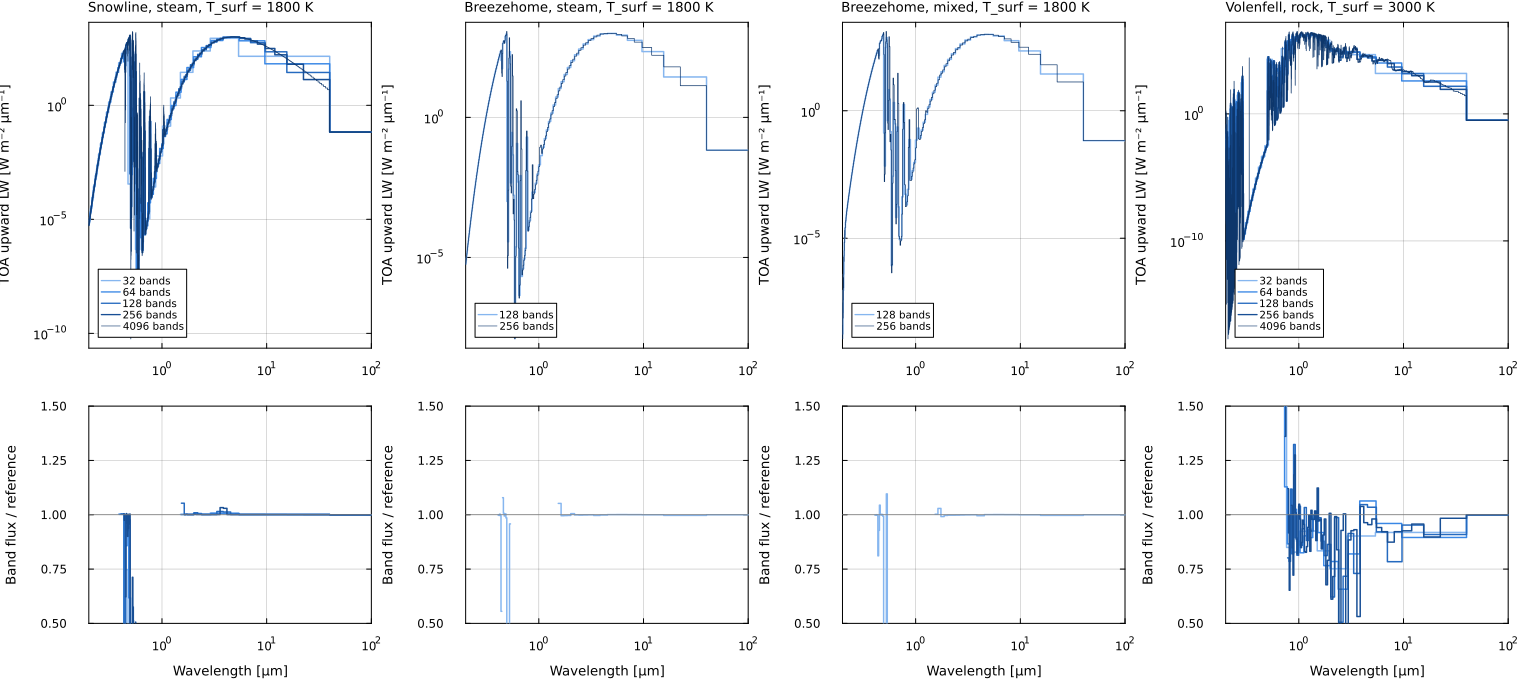

In [8]:
panels = map(S1) do (f, cn)
    ns = NB[f]
    entries = [((f, n, cn), "$n bands", ordcol(i, length(ns)), n == ns[end] ? 0.7 : 1.5) for (i, n) in enumerate(ns)]
    spectra_panels(@sprintf("%s, %s, T_surf = %.0f K", f, cn, CASES[cn].ts[2]), (f, ns[end], cn), entries, 2)
end
fig2rows(panels, "spectra_bands"; h=680)

## 2. Converged T(p) with few bands

The case is a magma ocean with a fixed surface temperature (2500 K for steam and mixed, 3000 K for rock vapour), solved for RCE with dry convection and radiation only. There is no condensation, no sensible heat and no Rayleigh scattering. Each solve starts from a dry adiabat with an isothermal stratosphere at T_surf/3 (steam, mixed) or T_surf/2 (rock vapour, which did not converge from T_surf/3 within 300 steps). The reference is the run with the most bands up to `N_RCE_MAX`. Converged profiles are not computed for the 4096-band files. One radiative transfer call takes about 0.6 s with them, and each Jacobian needs about 40 calls, so a solve would take tens of minutes.

Snowline   steam     32 bands  converged true   OLR      7307 W m⁻² (-27.60%)  net flux      7012 W m⁻²  max|T - T_ref|   36.6 K
Snowline   steam     64 bands  converged true   OLR      9673 W m⁻² ( -4.16%)  net flux      9379 W m⁻²  max|T - T_ref|   18.3 K


Snowline   steam    128 bands  converged true   OLR 1.009e+04 W m⁻² ( +0.00%)  net flux      9798 W m⁻²  max|T - T_ref|    0.0 K
Breezehome steam    128 bands  converged true   OLR 1.009e+04 W m⁻² ( +0.00%)  net flux      9798 W m⁻²  max|T - T_ref|    0.0 K


Breezehome mixed    128 bands  converged true   OLR 1.243e+04 W m⁻² ( +0.00%)  net flux 1.214e+04 W m⁻²  max|T - T_ref|    0.0 K
Volenfell  rock      32 bands  converged true   OLR 9.544e+05 W m⁻² (-23.99%)  net flux 9.541e+05 W m⁻²  max|T - T_ref|  179.5 K
Volenfell  rock      64 bands  converged true   OLR 1.097e+06 W m⁻² (-12.61%)  net flux 1.097e+06 W m⁻²  max|T - T_ref|   82.8 K
Volenfell  rock     128 bands  converged true   OLR 1.256e+06 W m⁻² ( +0.00%)  net flux 1.255e+06 W m⁻²  max|T - T_ref|    0.0 K


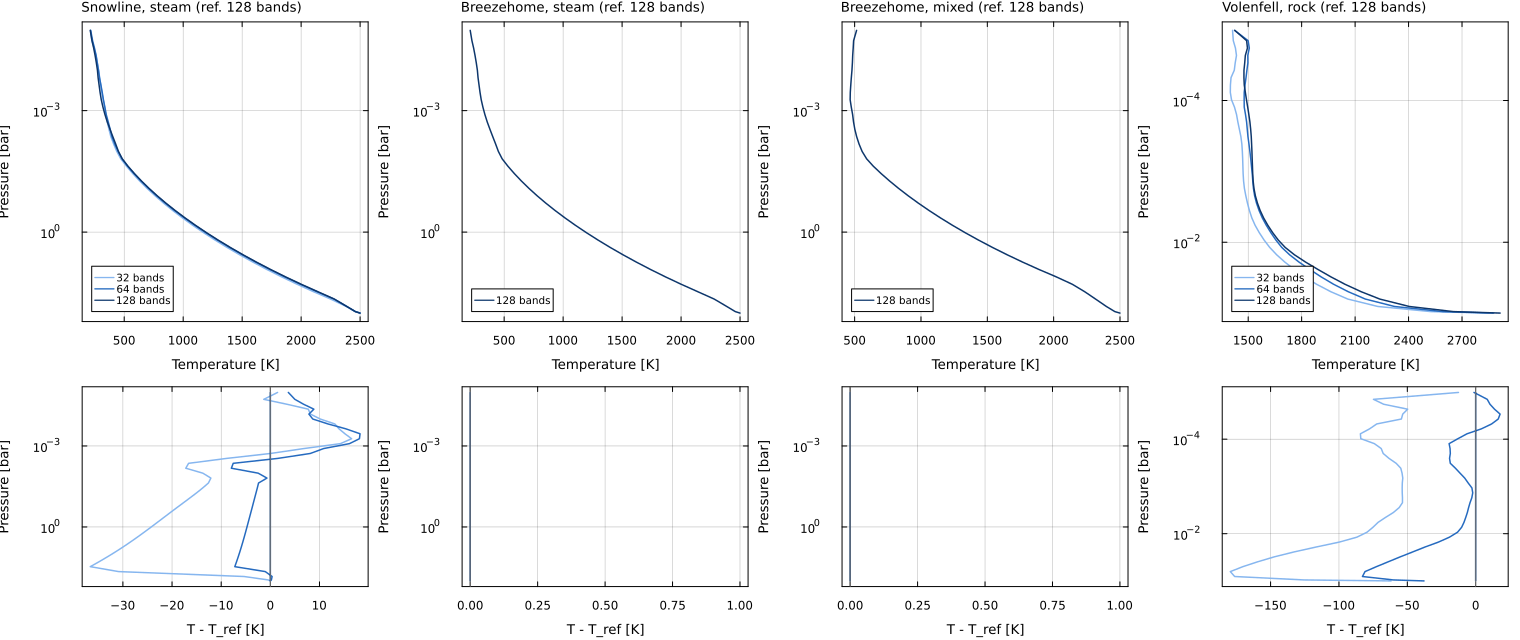

In [9]:
panels = map(S1) do (f, cn)
    ns = filter(<=(N_RCE_MAX), NB[f])
    kref = (f, ns[end], cn)
    rce_report(kref, [(f, n, cn) for n in ns])
    tp_panels("$f, $cn (ref. $(ns[end]) bands)", kref, [((f, n, cn), "$n bands", ordcol(i, length(ns))) for (i, n) in enumerate(ns)])
end
fig2rows(panels, "rce_bands")

## 3. Comparison with Honeyside and Oak

The steam case is run with Snowline, Breezehome, Honeyside and Oak. The mixed case (H₂O, CO₂, CO, SO₂) is run with Breezehome and Honeyside. The references are Snowline with the most bands (steam) and Breezehome with the most bands (mixed). These are new files, so the differences show how the old and new files disagree, not which is right.

Things to keep in mind:

* The Honeyside k-tables start at 3.2 × 10⁻⁴ bar. Above that, up to P_TOP = 10⁻⁵ bar, SOCRATES has to use values from outside its table.
* Rebinning the reference onto Honeyside and Oak bands is only accurate when the reference bands are much narrower than theirs. This holds for Snowline/4096. While Breezehome has only 128 bands, the mixed-case spectral error against Honeyside partly reflects the rebinning.
* The old and new files also differ in their line lists, continua, and the P–T grids of their k-tables, so a difference here does not by itself show an error in the new files.


steam case, reference Snowline/4096. Columns are T_surf = 1000, 1800, 2600 K
file       bands   OLR - OLR_ref [%]        spectral error [%]      
Snowline      32      +0.00   -0.24  -14.76     0.00    0.88   14.87
Snowline      64      +0.00   -0.10   -7.55     0.00    0.61    7.64
Snowline     128      +0.00   +0.01   -6.75     0.01    0.56    6.86
Snowline     256      -0.00   +0.13   -3.70     0.01    0.49    3.86
Snowline    4096      +0.00   +0.00   +0.00     0.00    0.00    0.00
Breezehome   128      +0.00   +0.01   -6.75     0.01    0.56    6.86


Breezehome   256      -0.00   +0.13   -3.70     0.01    0.49    3.86
Honeyside     48      -0.00   -0.65  -27.63     7.31    2.47   28.03
Oak          318      -0.00   -0.52  -19.69     7.32    2.37   20.12

mixed case, reference Breezehome/256. Columns are T_surf = 1000, 1800, 2600 K
file       bands   OLR - OLR_ref [%]        spectral error [%]      
Breezehome   128      +0.00   -0.24   -4.83     0.10    0.34    5.02
Breezehome   256      +0.00   +0.00   +0.00     0.00    0.00    0.00
Honeyside     48      +0.00   -0.87  -28.53    14.90    6.36   30.44


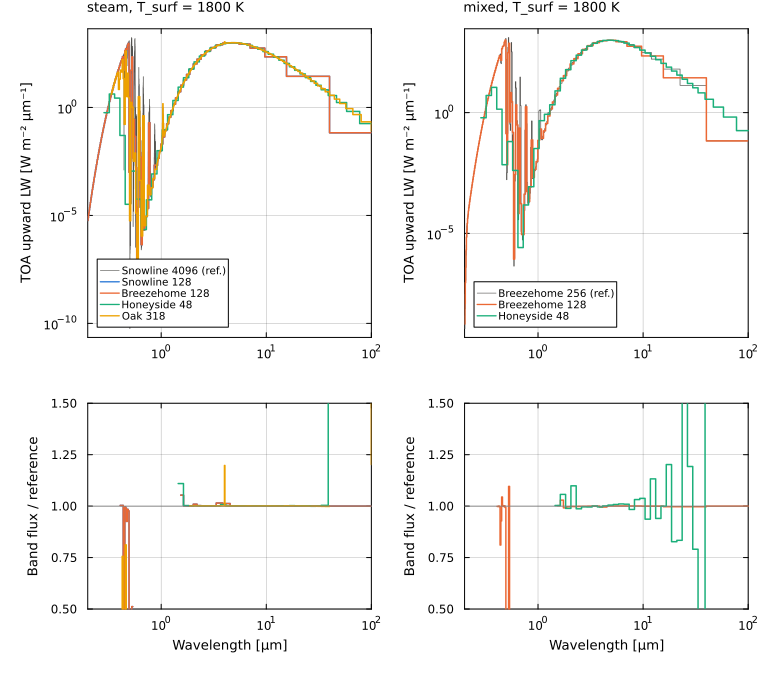

In [10]:
nmax(f) = maximum(NB[f])
nrce(f) = maximum(filter(<=(N_RCE_MAX), NB[f]))
S3 = [("steam", ("Snowline", nmax("Snowline"), "steam"),
       [("Snowline", nrce("Snowline")), ("Breezehome", nrce("Breezehome")), ("Honeyside", 48), ("Oak", 318)]),
      ("mixed", ("Breezehome", nmax("Breezehome"), "mixed"),
       [("Breezehome", nrce("Breezehome")), ("Honeyside", 48)])]

for (cn, kref, _) in S3
    report(cn, kref, [(j.fam, j.nb, cn) for j in JOBS if j.case == cn])
end

panels = map(S3) do (cn, kref, fs)
    entries = [((f, n, cn), "$f $n", FCOL[f], 1.5) for (f, n) in fs if (f, n, cn) != kref]
    pushfirst!(entries, (kref, "$(kref[1]) $(kref[2]) (ref.)", REFCOL, 0.7))
    spectra_panels(@sprintf("%s, T_surf = %.0f K", cn, CASES[cn].ts[2]), kref, entries, 2)
end
fig2rows(panels, "spectra_old"; h=680)

Converged T(p) for the same files, as in section 2. Differences are taken from the first new file in each panel.

Snowline   steam    128 bands  converged true   OLR 1.009e+04 W m⁻² ( +0.00%)  net flux      9798 W m⁻²  max|T - T_ref|    0.0 K
Breezehome steam    128 bands  converged true   OLR 1.009e+04 W m⁻² ( -0.00%)  net flux      9798 W m⁻²  max|T - T_ref|    0.0 K
Honeyside  steam     48 bands  converged true   OLR      3247 W m⁻² (-67.83%)  net flux      2953 W m⁻²  max|T - T_ref|  108.3 K
Oak        steam    318 bands  converged true   OLR      8476 W m⁻² (-16.02%)  net flux      8182 W m⁻²  max|T - T_ref|  128.9 K
Breezehome mixed    128 bands  converged true   OLR 1.243e+04 W m⁻² ( +0.00%)  net flux 1.214e+04 W m⁻²  max|T - T_ref|    0.0 K
Honeyside  mixed     48 bands  converged true   OLR      2883 W m⁻² (-76.81%)  net flux      2588 W m⁻²  max|T - T_ref|  267.6 K


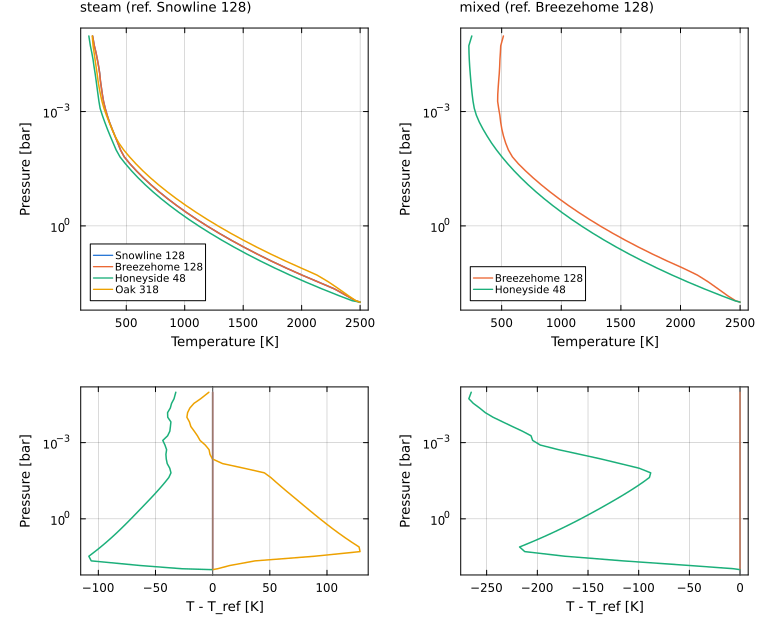

In [11]:
panels = map(S3) do (cn, _, fs)
    keys = [(f, n, cn) for (f, n) in fs]
    rce_report(keys[1], keys)
    tp_panels("$cn (ref. $(keys[1][1]) $(keys[1][2]))", keys[1], [(k, "$(k[1]) $(k[2])", FCOL[k[1]]) for k in keys])
end
fig2rows(panels, "rce_old")